In [7]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Annex 1 - Saltblock moving diagonally

__To make the recquired changes you can either modify the files yourself by follwing the instructions starting 2 cells below or you can execute the cell below__

In [23]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_diag_cen2_all_grid.nc
rm CANAL_saltblock_diag_cen4_all_grid.nc
rm CANAL_saltblock_diag_ubs_all_grid.nc
rm CANAL_saltblock_diag_fct2_all_grid.nc
rm CANAL_saltblock_diag_fct4_all_grid.nc


chmod -R a+x /"$DIR"/annex1_cfg/

bash /"$DIR"/annex1_cfg/diag_cfg.sh "$DIR"
bash "$DIR"/annex1_cfg/diag_istate.sh "$DIR"

bash /"$DIR"/annex1_cfg/cen_cfg.sh "$DIR"; sh /"$DIR"/annex1_cfg/fct_cfg.sh "$DIR"; bash /"$DIR"/annex1_cfg/ubs_cfg.sh "$DIR"


## Running the simulation

Change in ```usr_def_istate``` : 

```   
      CASE(1)    ! geostrophic zonal jet from -zjety to +zjety
         !
         ! temperature:
         pts(:,:,:,jp_tem) = 10._wp
         ! salinity:  
         pts(:,:,jpk,jp_sal) = 0._wp 
         DO jk=1, jpkm1
           !  WHERE( ABS(gphit) <= zjety )
            WHERE( ABS(gphit) <= zsy*0.5 .AND. ABS(glamt) <= zsx*0.5 ) ! for a square of salt
               pts(:,:,jk,jp_sal) = 35._wp
            ELSEWHERE
               pts(:,:,jk,jp_sal) = 30._wp
            END WHERE
            !pts(:, :, jk, jp_sal) = 30._wp+5._wp*EXP( - 0.5_wp * glamt(:,:)**2 / rn_lambda**2 )
         END DO
         ! velocities:
         pu(:,:,:) = 0._wp
         DO jk=1, jpkm1
            WHERE( ABS(gphit) <= zjety ) pu(:,:,jk) = rn_uzonal
         END DO
         pv(:,:,:) = 0._wp
         DO jk=1, jpkm1
            WHERE( ABS(glamt) <= zjetx ) pv(:,:,jk) = rn_uzonal
         END DO
         !
```

Change in ```usr_def_istate_ssh``` : 

```
      CASE(1)                      !==  geostrophic zonal jet from -zjety to +zjety  ==!
         !
         SELECT CASE( nn_fcase )
         CASE(0)                          !* f = f0 : ssh = - fuy / g
            WHERE( ABS(gphit) <= zjety .AND. ABS(glamt) <= zjetx )
               pssh(:,:) = - ff_t(:,:) * rn_uzonal *( gphit(:,:)-glamt(:,:)) * 1.e3_wp / grav
```

The value of ```rn_ppgphi0``` should be set to ```0```. This forces the Coriolis force to zero, the pressure field to be uniform so that it generates no slopes which is the only way to not generate any issue with the bi-periodicity of the domain.

Recompile with ```./makenemo -r CANAL```

In [24]:
#Insert below the name of the directory in which you will run the simulations 
rep = ''


cen2 = xr.open_dataset(rep+'CANAL_saltblock_diag_cen2_all_grid.nc')
cen4 = xr.open_dataset(rep+'CANAL_saltblock_diag_cen4_all_grid.nc')
ubs = xr.open_dataset(rep+'CANAL_saltblock_diag_ubs_all_grid.nc')
fct2 = xr.open_dataset(rep+'CANAL_saltblock_diag_fct2_all_grid.nc')
fct4 = xr.open_dataset(rep+'CANAL_saltblock_diag_fct4_all_grid.nc')



In [27]:
def show_t (t_list, param, title, file, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"

    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(10, 3))
    for i, t in enumerate(t_list) : 
        # We select and show the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', cmap='coolwarm')
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])
    plt.show()
    dataset.close()

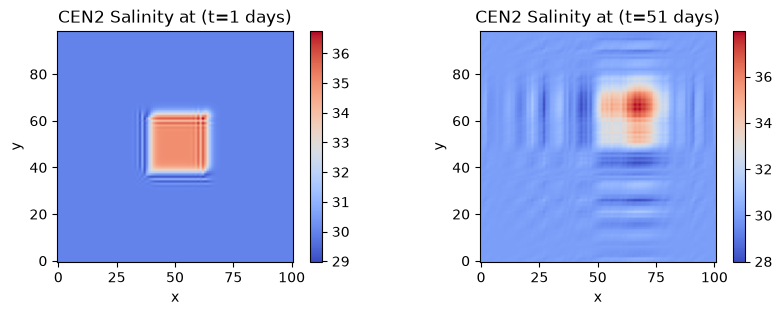

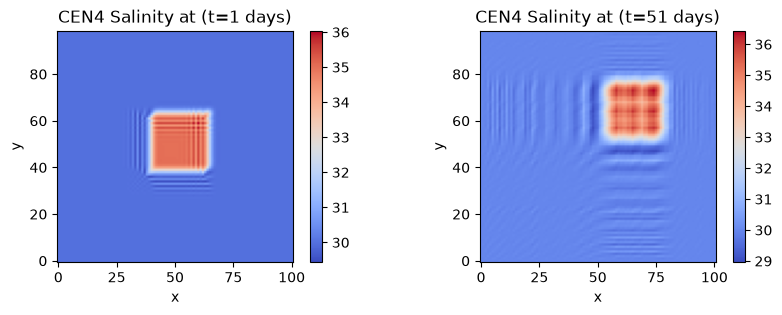

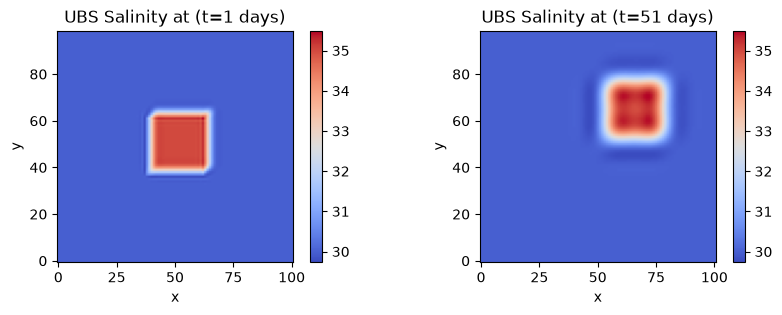

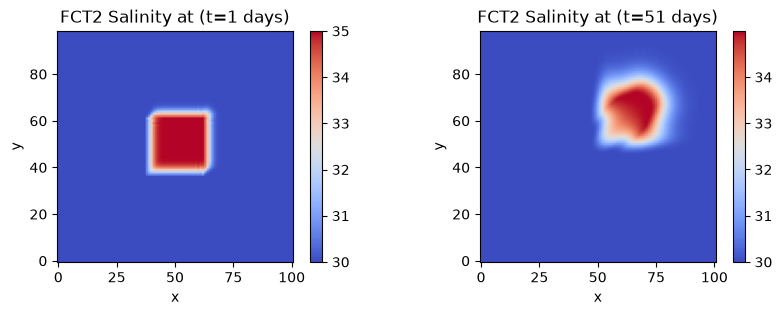

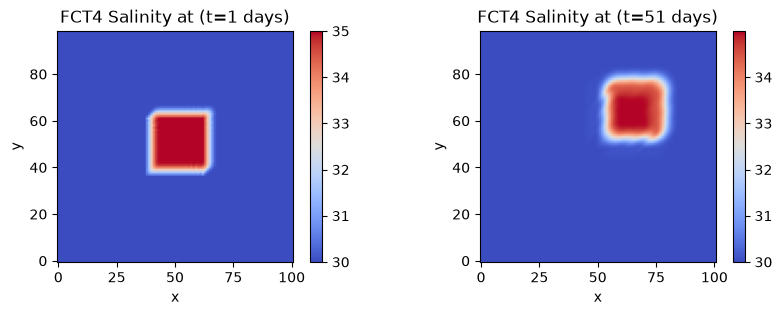

In [28]:
show_t([0, 50], 'soce', 'CEN2 Salinity', 'CANAL_saltblock_diag_cen2_all_grid.nc')
show_t([0, 50], 'soce', 'CEN4 Salinity', 'CANAL_saltblock_diag_cen4_all_grid.nc')
show_t([0, 50], 'soce', 'UBS Salinity', 'CANAL_saltblock_diag_ubs_all_grid.nc')
show_t([0, 50], 'soce', 'FCT2 Salinity', 'CANAL_saltblock_diag_fct2_all_grid.nc')
show_t([0, 50], 'soce', 'FCT4 Salinity', 'CANAL_saltblock_diag_fct4_all_grid.nc')




In [31]:
def side_lobes(t_list, param, title, file, mode, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"

    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(10, 3))
    for i, t in enumerate(t_list) : 
        # We select and show the side lobes of the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        # Creation of a mask to highlight the side-lobes
        mask0_under = (data < 30)
        mask0_over = (data > 35)

        if mode == 'binary': 
            side_lobes = mask0_over | mask0_under
            im = axes[i].imshow(side_lobes, origin='lower', cmap= ListedColormap(['blue', 'yellow']))
            axes[i].set_title(f'Placement of the side lobes of {title} at time {t+1}')
            axes[i].set_xlabel('x')
            axes[i].set_ylabel('y')
            fig.colorbar(im, ax=axes[i])
        elif mode == 'magnitude': 
            under = data*mask0_under
            over = data*mask0_over

            under = abs(under-30)
            under = under*mask0_under

            over = abs(over-35)
            over = over*mask0_over

            side_lobes = over + under
            min_ = side_lobes.min()
            max_ = side_lobes.max()
            im = axes[i].imshow(side_lobes, origin='lower', cmap='YlOrRd', vmin = min_, vmax = max_)
            axes[i].set_title(f'Magnitude of the side lobes of {title} at time {t+1}')
            axes[i].set_xlabel('x')
            axes[i].set_ylabel('y')
            fig.colorbar(im, ax=axes[i])
        else : 
            print(f"{mode} mode does not exist")

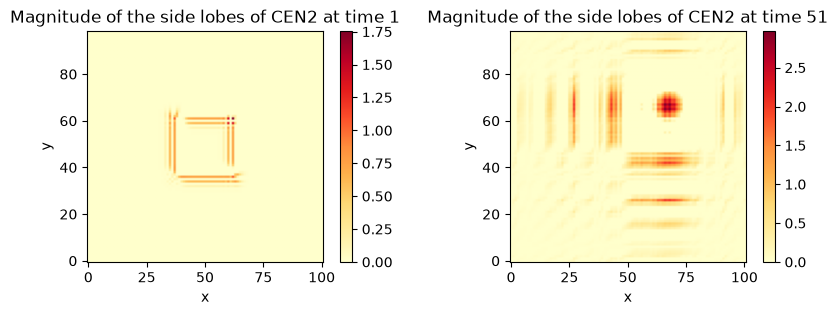

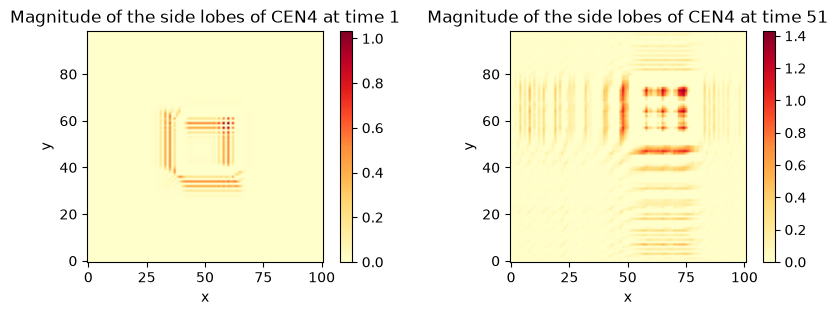

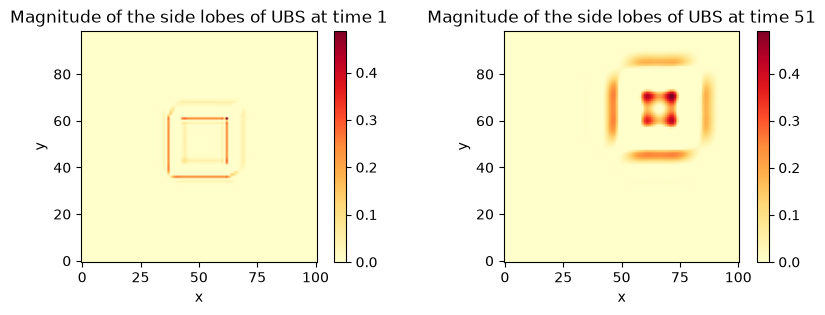

In [45]:
side_lobes([0, 50], 'soce', 'CEN2', 'CANAL_saltblock_diag_cen2_all_grid.nc', mode='magnitude', rep=rep)
side_lobes([0, 50], 'soce', 'CEN4', 'CANAL_saltblock_diag_cen4_all_grid.nc', mode='magnitude', rep=rep)
side_lobes([0, 50], 'soce', 'UBS', 'CANAL_saltblock_diag_ubs_all_grid.nc', mode='magnitude', rep=rep)

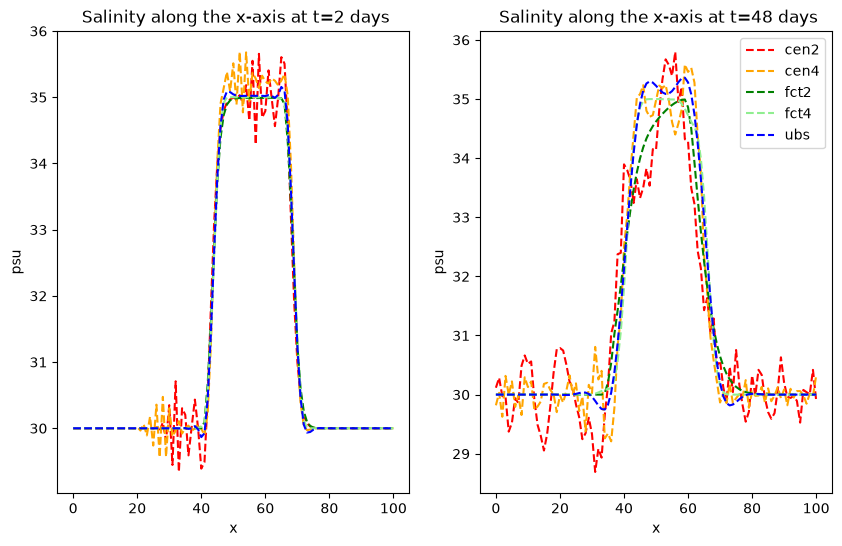

In [46]:
t0, t1 = 1, 47

fig, ax = plt.subplots(1, 2, figsize=(10,6))


ax[0].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
ax[0].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=t0, y_grid_T=50, deptht=0), '--', color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_title(f' Salinity along the x-axis at t={t0+1} days')


ax[1].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
ax[1].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=t1, y_grid_T=50, deptht=0), '--', color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_title(f' Salinity along the x-axis at t={t1+1} days')

plt.legend()

Text(0, 0.5, 'Salinity')

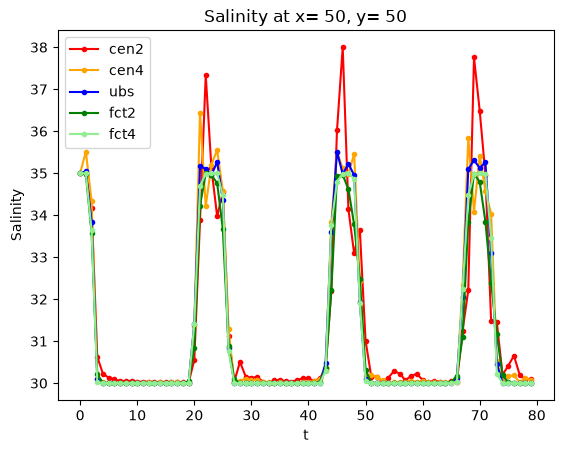

In [47]:

dataset = cen2['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, 'r.-', label = 'cen2')

dataset = cen4['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, '.-', color='orange', label = 'cen4')


dataset = ubs['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, 'b.-', label = 'ubs')


dataset = fct2['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, 'g.-', label = 'fct2')

dataset = fct4['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, '.-', color='lightgreen', label = 'fct4')

plt.legend()
plt.title(f"Salinity at x= {xmid}, y= {ymid}")
plt.xlabel('t')
plt.ylabel('Salinity')
   

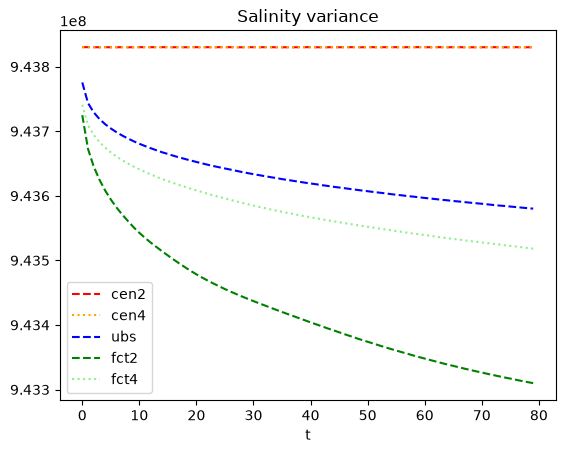

In [51]:
dataset = cen2['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, '--', color='red', label = 'cen2')

dataset = cen4['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, ':', color='orange', label = 'cen4')


dataset = ubs['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, '--', color='blue', label = 'ubs')

dataset = fct2['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, '--', color='green', label = 'fct2')

dataset = fct4['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, ':', color='lightgreen', label = 'fct4')


plt.title("Salinity variance")
plt.xlabel('t')

plt.legend()

In [14]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

chmod -R a+x /"$DIR"/annex1_cfg/

bash /"$DIR"/annex1_cfg/end_diag.sh "$DIR"



339c339
<                pssh(:,:) = - zf0 * rn_uzonal *gphit(:,:)* 1e3_wp /grav                  


---
>                pssh(:,:) = - zf0 * rn_uzonal *gphit(:,:)* 1e3_wp /grav                   
Changes applied. Saving : /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/MY_SRC/usrdef_istate.F90.bak
Compilation lancée depuis : /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo



You are compiling an existing configuration CANAL with sub-components: OCE


Creating /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/WORK = /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/src/OCE for CANAL

/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/MY_SRC content is linked to /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/WORK

--------------------------------------------------------------------------------
Compilation
--------------------------------------------------------------------------------

Build command started on Fri Oct  2 14:31:30 20

Use of uninitialized value in numeric gt (>) at /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/ext/FCM/bin/../lib/Fcm/BuildTask.pm line 176.


No. of pre-processed file: 1
->Pre-process: 0 second
->Scan dependency: start
No. of file scanned for dependency: 1
/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/Makefile: updated
->Scan dependency: 0 second
->Generate Fortran interface: start
->Generate Fortran interface: 0 second
->Make: start
mpif90 -o usrdef_istate.o -I/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/inc -i4 -r8 -O3 -fp-model strict -march=core-avx2 -fno-alias -I/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/xios-3.0.x/inc -I/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/include -I/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/include -c /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/ppsrc/nemo/usrdef_istate.f90
mpif90 -o restart.o -I/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/inc -i4 -r8 -O3 -fp-model stric

ar: creating /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/tmp/lib__fcm__nemo.a


mpif90 -o nemo.exe /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/obj/nemo.o -L/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/BLD/lib -l__fcm__nemo -Wl,-rpath,/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/lib -Wl,-rpath,/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/lib -Wl,-rpath,/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/xios-3.0.x/lib -Wl,-rpath,notdef/lib -L/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/xios-3.0.x/lib -lxios -lstdc++ -L/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/lib -lnetcdff -L/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/lib -lnetcdf -L/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/util_nemo/lib -lhdf5_hl -lhdf5 -L -lcurl  -lz  -lm
->Make: 29 seconds
->TOTAL: 30 seconds
Build command finished on Fri Oct  2 14:32:00 2026.

-----------------------